In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("water_potability.csv")
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [2]:
# Menampilkan ringkasan informasi dari dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [3]:
# Menampilkan statistik deskriptif dari dataset
df.describe(include="all")

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


In [4]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

ph                 491
Sulfate            781
Trihalomethanes    162
dtype: int64

In [5]:
# Menentukan kolom dengan missing values kurang dari 1000
# dan kolom dengan missing values 1000 atau lebih
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

print("Kolom dengan missing values kurang dari 1000:", list(less))
print("Kolom dengan missing values 1000 atau lebih:", list(over))

Kolom dengan missing values kurang dari 1000: ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability']
Kolom dengan missing values 1000 atau lebih: []


In [6]:
# Mengisi missing values pada kolom numerik menggunakan median
numeric_features = df[less].select_dtypes(include=["number"]).columns
df[numeric_features] = df[numeric_features].fillna(df[numeric_features].median())

# Potability adalah target, bukan fitur prediktor
numeric_predictors = [col for col in numeric_features if col != "Potability"]

In [7]:
# Dataset ini tidak memiliki kolom kategorikal berbentuk teks,
# sehingga pengisian missing values dengan mode untuk kategori tidak diperlukan.
categorical_features = df.select_dtypes(include=["object", "str", "category"]).columns
print("Kolom kategorikal:", list(categorical_features))

Kolom kategorikal: []


In [8]:
# Menghapus kolom yang memiliki terlalu banyak missing values (jika ada)
df = df.drop(columns=over)
print("Ukuran dataset setelah pemeriksaan missing values:", df.shape)

Ukuran dataset setelah pemeriksaan missing values: (3276, 10)


In [9]:
# Memeriksa kembali missing values
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

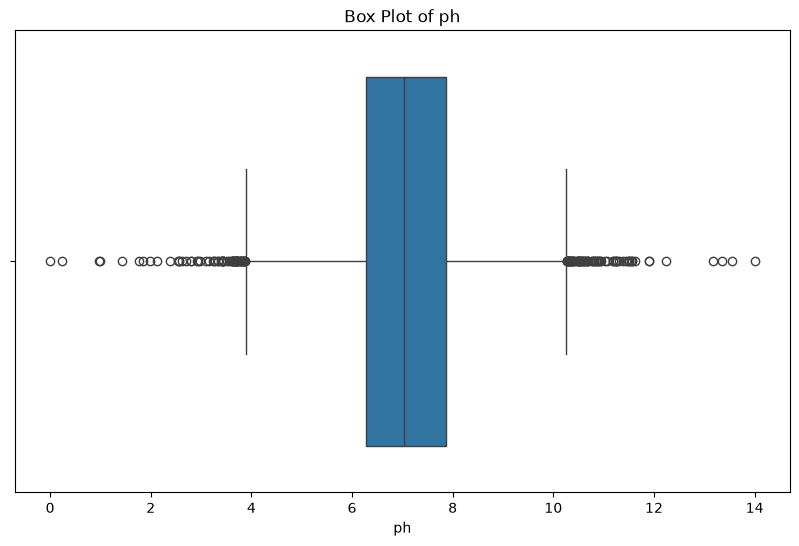

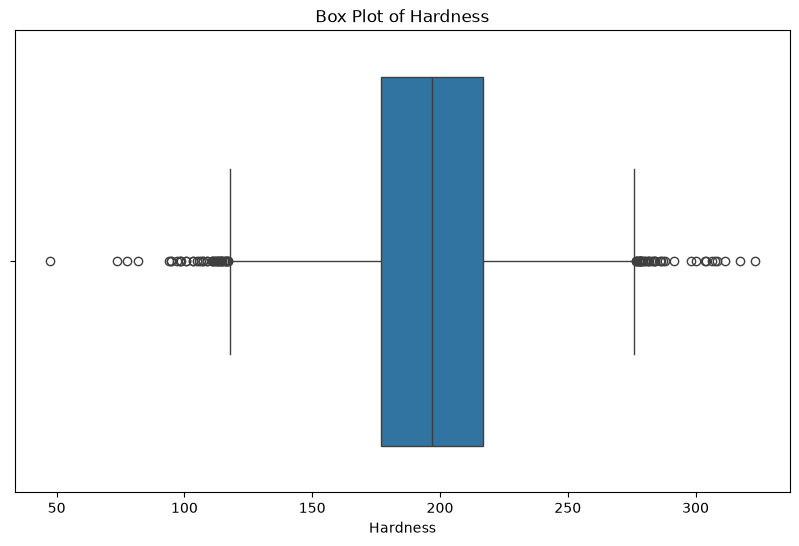

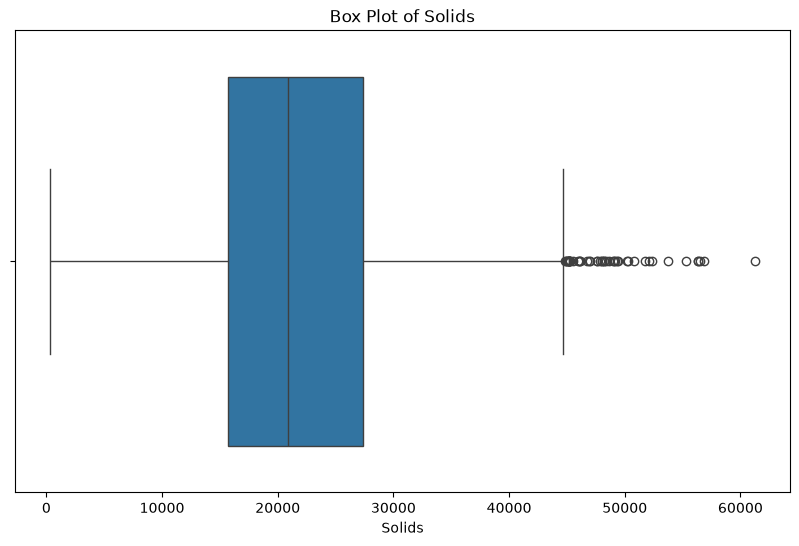

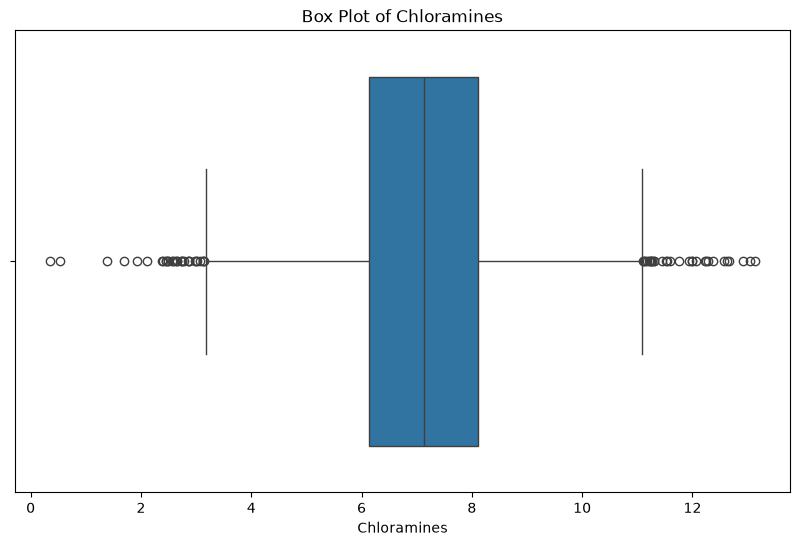

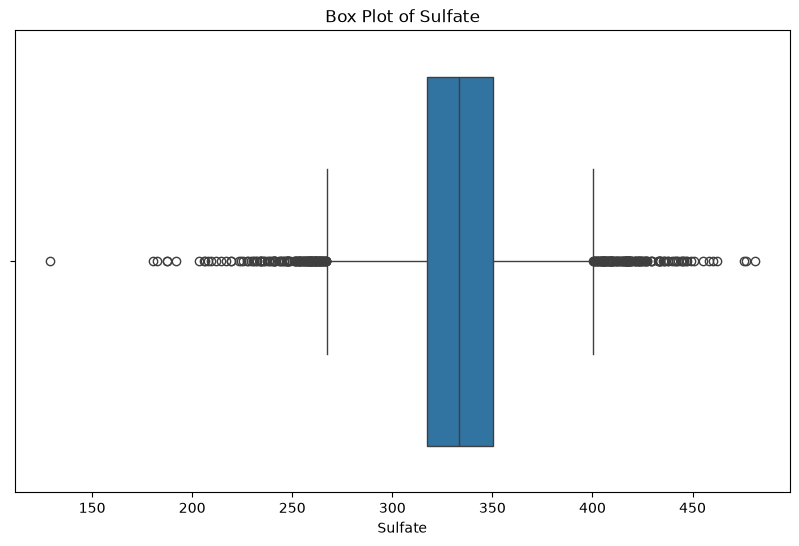

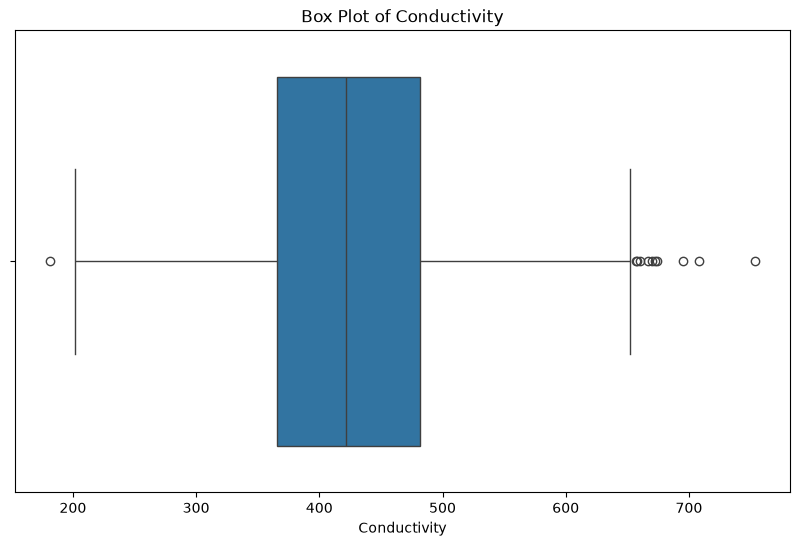

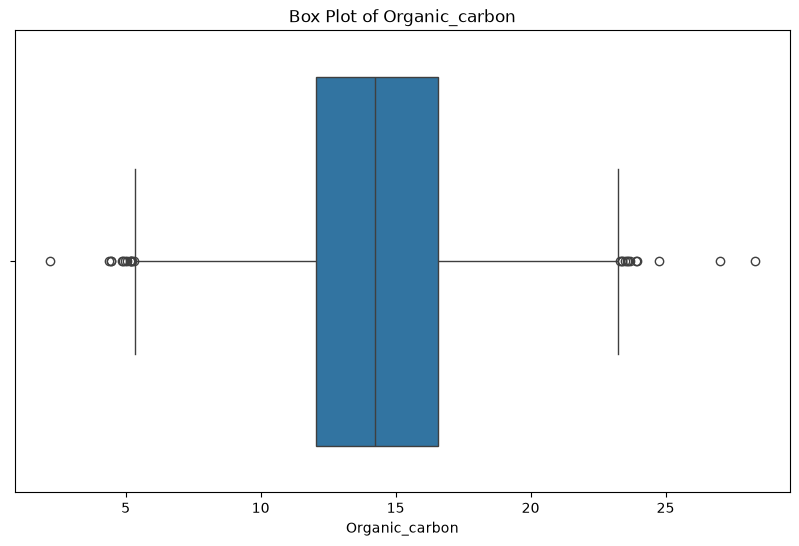

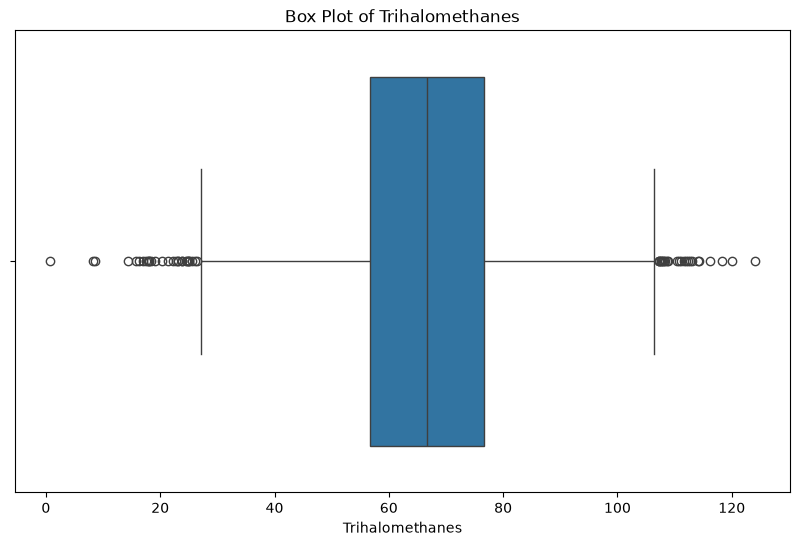

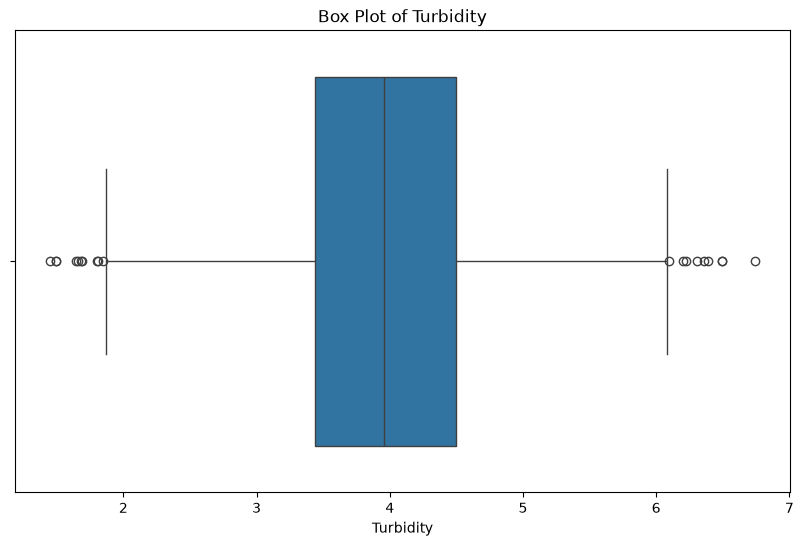

In [10]:
# Menampilkan Box Plot untuk setiap fitur numerik, tanpa kolom target
for feature in numeric_predictors:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f"Box Plot of {feature}")
    plt.show()

In [11]:
# Mengidentifikasi outlier menggunakan IQR pada fitur prediktor
Q1 = df[numeric_predictors].quantile(0.25)
Q3 = df[numeric_predictors].quantile(0.75)
IQR = Q3 - Q1

In [12]:
# Menyaring baris yang tidak memiliki outlier pada fitur prediktor
condition = ~(
    (df[numeric_predictors] < (Q1 - 1.5 * IQR)) |
    (df[numeric_predictors] > (Q3 + 1.5 * IQR))
).any(axis=1)

df = df.loc[condition].copy()
print("Ukuran dataset setelah penyaringan IQR:", df.shape)

Ukuran dataset setelah penyaringan IQR: (2666, 10)


In [13]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik saja; Potability tidak distandardisasi
scaler = StandardScaler()
df[numeric_predictors] = scaler.fit_transform(df[numeric_predictors])
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,-0.024698,0.276380,-0.087788,0.133760,1.318170,1.731801,-1.220488,1.379017,-1.312414,0
2,0.849411,0.958501,-0.199087,1.531834,-0.019184,-0.090093,0.796898,-0.001966,-1.190445,0
3,1.028484,0.610743,0.067098,0.670947,0.879328,-0.782072,1.284355,2.275289,0.876799,0
4,1.666523,-0.562404,-0.442764,-0.399530,-0.884687,-0.342620,-0.854093,-2.312822,0.149055,0
5,-1.219937,-0.308120,0.916600,0.306890,-0.260491,-1.817403,-1.836085,-0.774144,-1.842654,0


In [14]:
# Histogram sebelum dan sesudah standardisasi
# Simpan salinan data asli sebelum standardisasi untuk perbandingan yang benar.
# Jika sel standardisasi di atas sudah dijalankan, gunakan salinan yang dibuat
# pada sel alternatif berikut jika ingin membandingkan ulang.

In [15]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()
print("Jumlah baris duplikat:", duplicates.sum())
df[duplicates].head()

Jumlah baris duplikat: 0


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability


In [16]:
# Menghapus baris duplikat
df = df.drop_duplicates()
print("DataFrame setelah menghapus duplikat:")
df.head()

DataFrame setelah menghapus duplikat:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,-0.024698,0.276380,-0.087788,0.133760,1.318170,1.731801,-1.220488,1.379017,-1.312414,0
2,0.849411,0.958501,-0.199087,1.531834,-0.019184,-0.090093,0.796898,-0.001966,-1.190445,0
3,1.028484,0.610743,0.067098,0.670947,0.879328,-0.782072,1.284355,2.275289,0.876799,0
4,1.666523,-0.562404,-0.442764,-0.399530,-0.884687,-0.342620,-0.854093,-2.312822,0.149055,0
5,-1.219937,-0.308120,0.916600,0.306890,-0.260491,-1.817403,-1.836085,-0.774144,-1.842654,0


In [17]:
# Memeriksa kolom kategorikal
category_features = df.select_dtypes(include=["object", "str", "category"]).columns
df[category_features]

""
0
2
3
4
5
...
3270
3272
3273
3274


In [18]:
# One-Hot Encoding tidak diperlukan karena tidak ada kolom kategorikal berbentuk teks.
# Baris berikut tetap dapat digunakan secara umum jika nantinya ada kolom kategori:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,-0.024698,0.276380,-0.087788,0.133760,1.318170,1.731801,-1.220488,1.379017,-1.312414,0
2,0.849411,0.958501,-0.199087,1.531834,-0.019184,-0.090093,0.796898,-0.001966,-1.190445,0
3,1.028484,0.610743,0.067098,0.670947,0.879328,-0.782072,1.284355,2.275289,0.876799,0
4,1.666523,-0.562404,-0.442764,-0.399530,-0.884687,-0.342620,-0.854093,-2.312822,0.149055,0
5,-1.219937,-0.308120,0.916600,0.306890,-0.260491,-1.817403,-1.836085,-0.774144,-1.842654,0


In [19]:
from sklearn.preprocessing import LabelEncoder

# Label Encoding tidak diperlukan karena dataset ini tidak memiliki kolom teks kategorikal.
# Kode ini disiapkan agar alurnya sejalan dengan referensi.
df_lencoder = df.copy()
for col in category_features:
    label_encoder = LabelEncoder()
    df_lencoder[col] = label_encoder.fit_transform(df_lencoder[col].astype(str))

df_lencoder.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,-0.024698,0.276380,-0.087788,0.133760,1.318170,1.731801,-1.220488,1.379017,-1.312414,0
2,0.849411,0.958501,-0.199087,1.531834,-0.019184,-0.090093,0.796898,-0.001966,-1.190445,0
3,1.028484,0.610743,0.067098,0.670947,0.879328,-0.782072,1.284355,2.275289,0.876799,0
4,1.666523,-0.562404,-0.442764,-0.399530,-0.884687,-0.342620,-0.854093,-2.312822,0.149055,0
5,-1.219937,-0.308120,0.916600,0.306890,-0.260491,-1.817403,-1.836085,-0.774144,-1.842654,0


In [20]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage
}).sort_values(by="Missing Values", ascending=False)

missing_data[missing_data["Missing Values"] > 0]

,Missing Values,Percentage


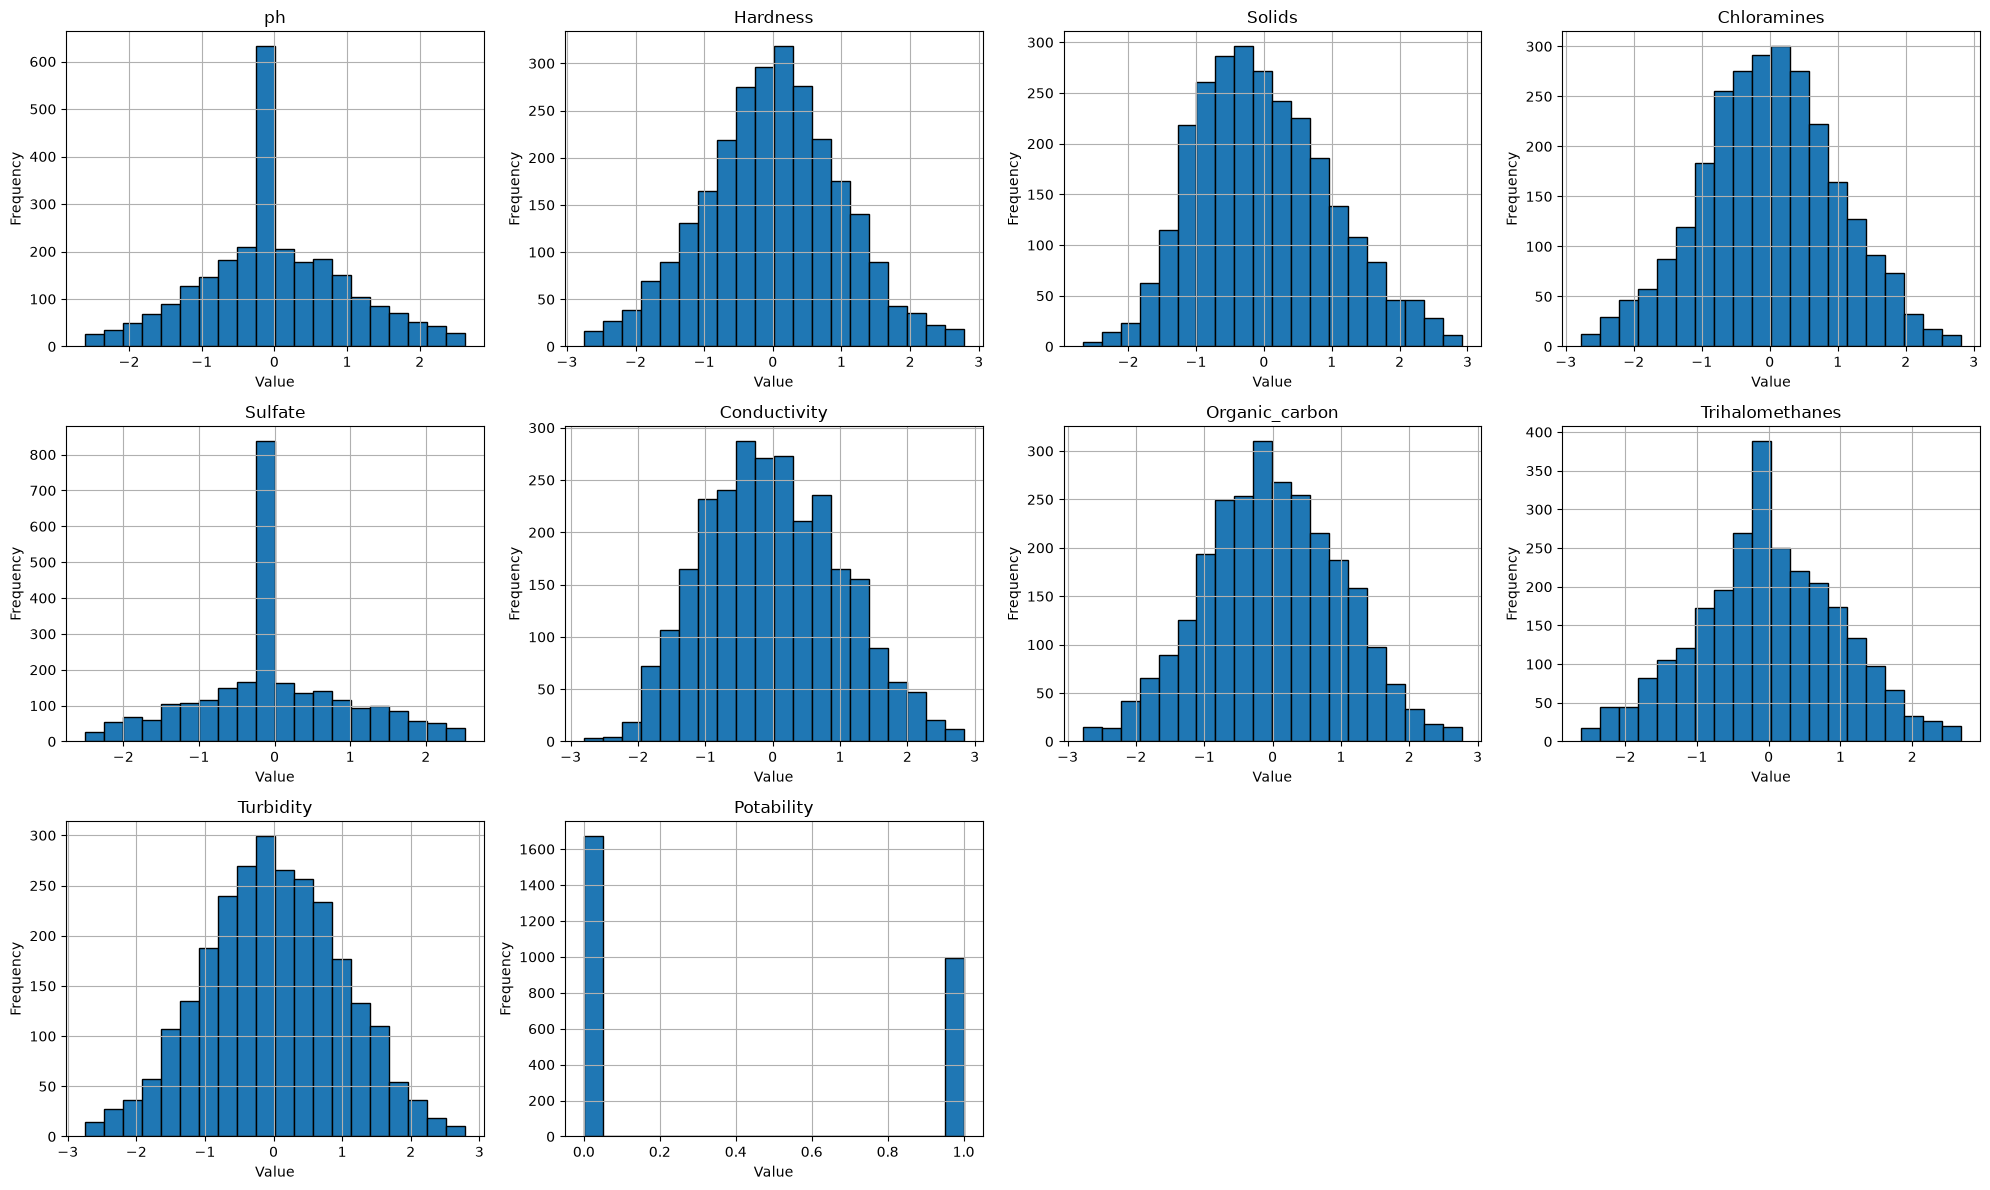

In [21]:
# Membuat histogram untuk setiap variabel
num_vars = df_lencoder.shape[1]
n_cols = 4
n_rows = -(-num_vars // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = axes.flatten()

for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor="black")
    axes[i].set_title(column)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

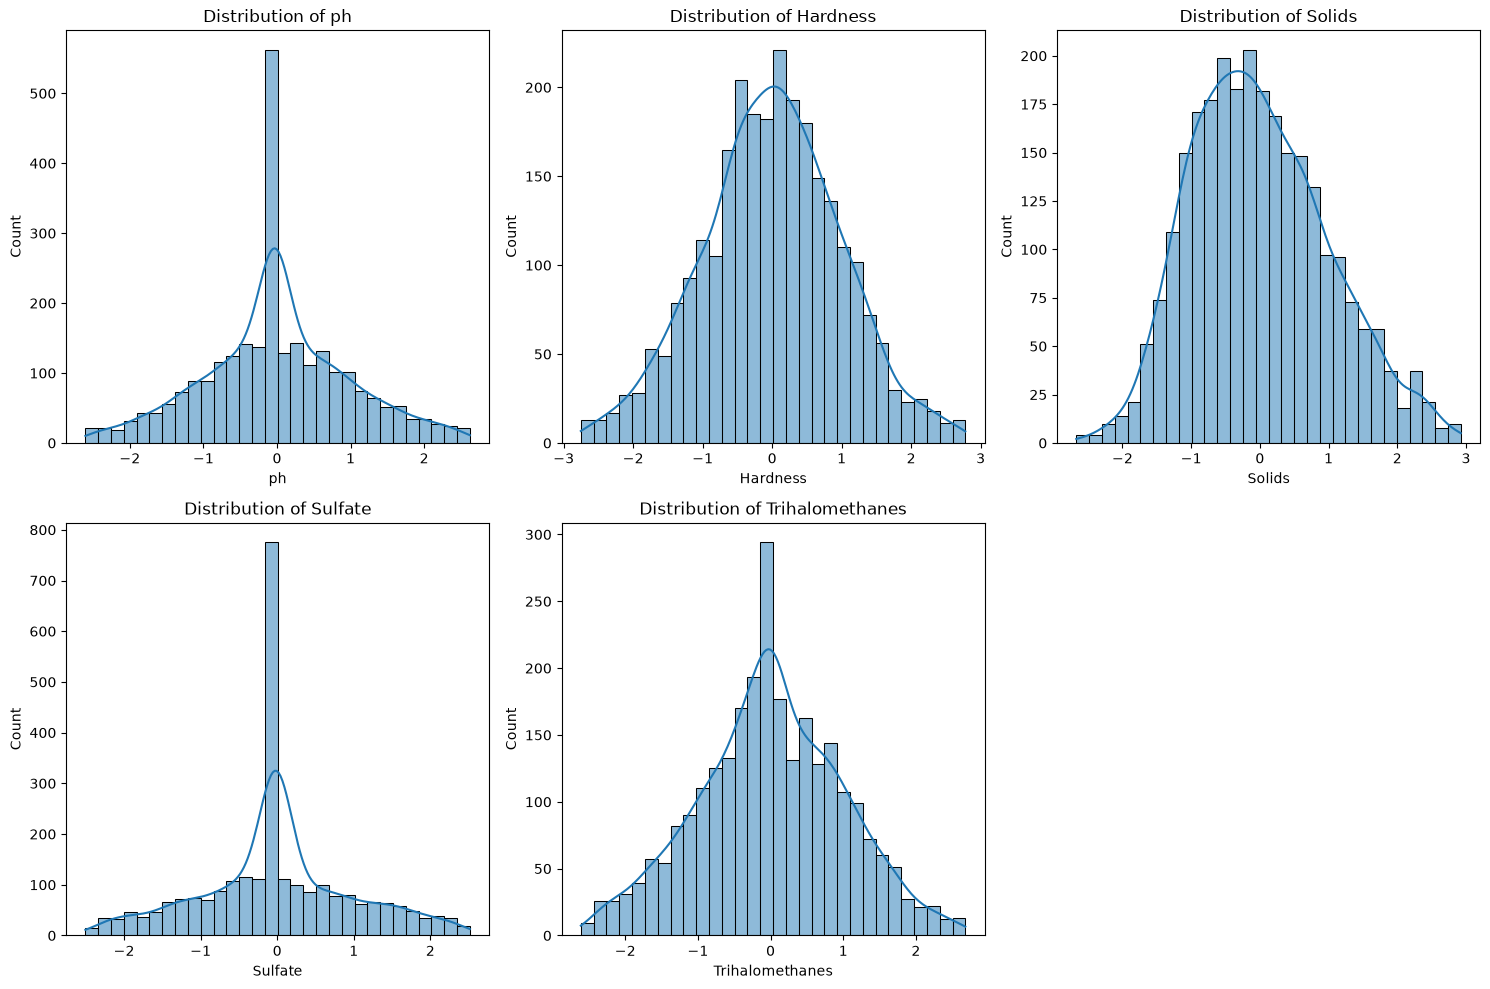

In [22]:
# Visualisasi distribusi beberapa kolom yang ada pada dataset Water Potability
columns_to_plot = ["ph", "Hardness", "Solids", "Sulfate", "Trihalomethanes"]

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f"Distribution of {column}")

plt.tight_layout()
plt.show()

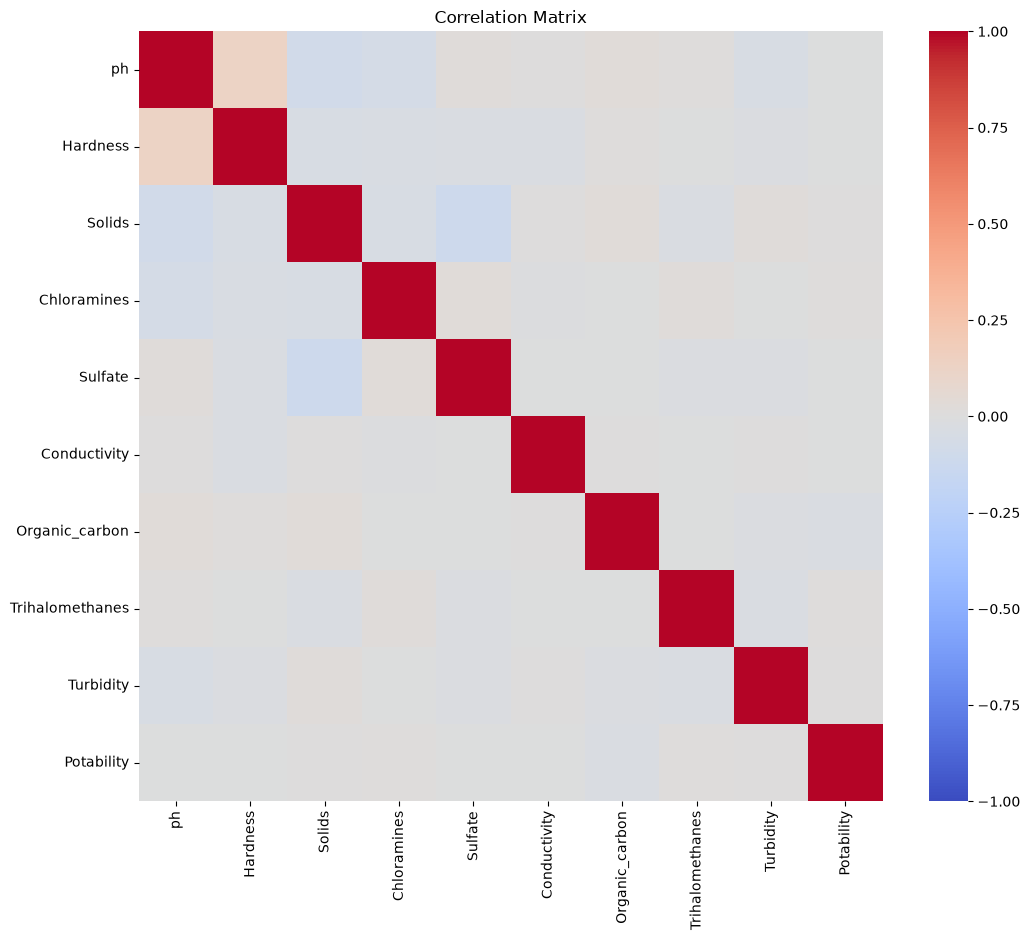

In [23]:
# Visualisasi korelasi antarvariabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

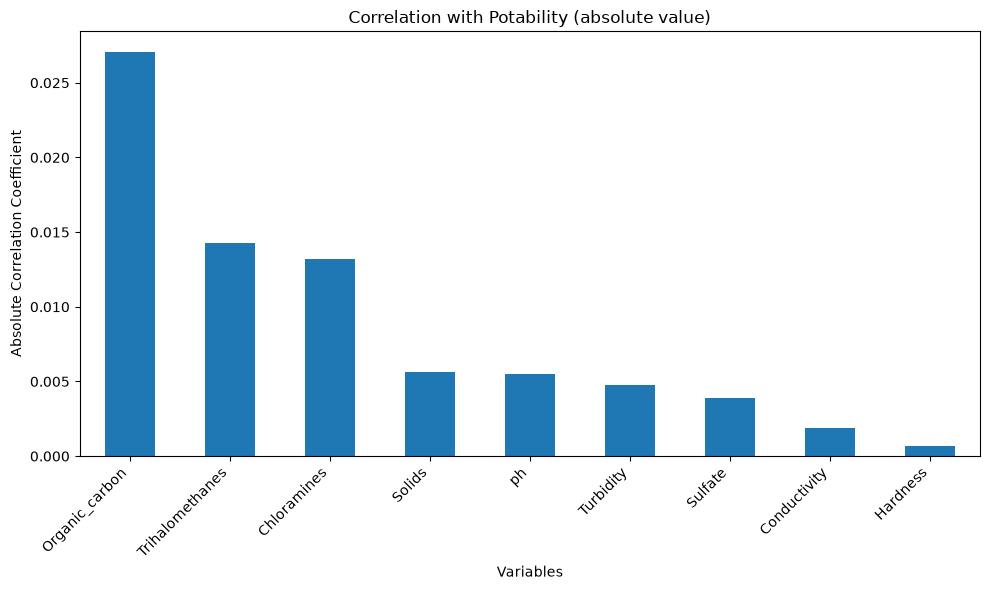

Organic_carbon     0.027090
Trihalomethanes    0.014274
Chloramines        0.013195
Solids             0.005600
ph                 0.005499
Turbidity          0.004761
Sulfate            0.003876
Conductivity       0.001886
Hardness           0.000710
Name: Potability, dtype: float64

In [24]:
# Menghitung korelasi antara target Potability dan variabel lainnya
target_corr = df_lencoder.corr()["Potability"].drop("Potability")
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind="bar")
plt.title("Correlation with Potability (absolute value)")
plt.xlabel("Variables")
plt.ylabel("Absolute Correlation Coefficient")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

target_corr_sorted

In [25]:
import sklearn

In [26]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns=["Potability"])
y = df_lencoder["Potability"]

In [27]:
from sklearn.model_selection import train_test_split

# Membagi dataset menjadi training dan testing
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)

In [28]:
# Menghitung panjang/jumlah data
print("Jumlah data: ", len(X))

# Menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ", len(x_train))

# Menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ", len(x_test))

Jumlah data:  2666
Jumlah data latih:  2132
Jumlah data test:  534
